In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import random
import tensorflow as tf
from tensorflow.keras import optimizers, losses, metrics, callbacks, layers, models

In [1]:
!pip install -q kaggle
!kaggle datasets download -d bhavikjikadara/dog-and-cat-classification-dataset --unzip
print("Dataset contents:", os.listdir('.'))

Dataset URL: https://www.kaggle.com/datasets/bhavikjikadara/dog-and-cat-classification-dataset
License(s): apache-2.0
100% 775M/775M [00:04<00:00, 163MB/s]

Dataset contents: ['.config', 'PetImages', 'sample_data']


In [4]:
# Define paths
base_dir = 'PetImages'
categories = ['Cat', 'Dog']

target_base_dir = 'dataset_split'
train_dir = os.path.join(target_base_dir, 'train')
val_dir = os.path.join(target_base_dir, 'validation')
test_dir = os.path.join(target_base_dir, 'test')

# Create target directories
for category in categories:
    os.makedirs(os.path.join(train_dir, category), exist_ok=True)
    os.makedirs(os.path.join(val_dir, category), exist_ok=True)
    os.makedirs(os.path.join(test_dir, category), exist_ok=True)

for category in categories:
    category_path = os.path.join(base_dir, category)

    # Filter out non-image files / corrupt or empty files
    all_files = []
    for f in os.listdir(category_path):
        file_path = os.path.join(category_path, f)
        if os.path.isfile(file_path) and f.lower().endswith(('.jpg', '.jpeg', '.png')) and os.path.getsize(file_path) > 0:
            all_files.append(f)

    # Step 1: Split 70% Train and 30% Temp (which will be split into Validation & Test)
    train_files, temp_files = train_test_split(all_files, test_size=0.30, random_state=42)

    # Step 2: Split the 30% Temp evenly into Validation (15% total) and Test (15% total)
    val_files, test_files = train_test_split(temp_files, test_size=0.50, random_state=42)

    # Copy files to respective directories
    for f in train_files:
        shutil.copy(os.path.join(category_path, f), os.path.join(train_dir, category, f))
    for f in val_files:
        shutil.copy(os.path.join(category_path, f), os.path.join(val_dir, category, f))
    for f in test_files:
        shutil.copy(os.path.join(category_path, f), os.path.join(test_dir, category, f))

print("Data split completed successfully with a 70% / 15% / 15% ratio!")
for folder, label in [(train_dir, 'Train'), (val_dir, 'Validation'), (test_dir, 'Test')]:
    cat_count = len(os.listdir(os.path.join(folder, 'Cat')))
    dog_count = len(os.listdir(os.path.join(folder, 'Dog')))
    print(f"{label} -> Cats: {cat_count} | Dogs: {dog_count} | Total: {cat_count + dog_count}")

Data split completed successfully with a 70% / 15% / 15% ratio!
Train -> Cats: 8749 | Dogs: 8749 | Total: 17498
Validation -> Cats: 1875 | Dogs: 1875 | Total: 3750
Test -> Cats: 1875 | Dogs: 1875 | Total: 3750


In [5]:
splits = ['train', 'validation', 'test']
categories = ['Cat', 'Dog']
base_split_dir = 'dataset_split'

data_list = []
corrupt_files = []

# Scan the directories to collect dimensions and check for corrupt files
for split in splits:
    for category in categories:
        folder_path = os.path.join(base_split_dir, split, category)
        for f in os.listdir(folder_path):
            file_path = os.path.join(folder_path, f)
            try:
                with Image.open(file_path) as img:
                    width, height = img.size
                    data_list.append({
                        'split': split,
                        'category': category,
                        'filename': f,
                        'width': width,
                        'height': height,
                        'pixels': width * height
                    })
            except Exception as e:
                corrupt_files.append((file_path, str(e)))

# Convert to DataFrame
df_meta = pd.DataFrame(data_list)

# 1. Summary Statistics for each split
print("=== IMAGE SIZE STATISTICS ===")
for split in splits:
    split_df = df_meta[df_meta['split'] == split]
    print(f"\nSplit: {split.upper()}")
    print(f"  Minimum size (WxH): {int(split_df['width'].min())} x {int(split_df['height'].min())}")
    print(f"  Average size (WxH): {int(split_df['width'].mean())} x {int(split_df['height'].mean())}")
    print(f"  Maximum size (WxH): {int(split_df['width'].max())} x {int(split_df['height'].max())}")

# Report corrupt files if any exist
if corrupt_files:
    print(f"\n=== WARNING: Found {len(corrupt_files)} Corrupt/Unreadable Image(s) ===")
    for path, err in corrupt_files[:10]:
         print(f"  Corrupt: {path} - {err}")
    if len(corrupt_files) > 10:
         print("  ... and more.")
else:
    print("\n=== NO CORRUPT IMAGES DETECTED ===")

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


=== IMAGE SIZE STATISTICS ===

Split: TRAIN
  Minimum size (WxH): 42 x 33
  Average size (WxH): 404 x 361
  Maximum size (WxH): 500 x 500

Split: VALIDATION
  Minimum size (WxH): 4 x 4
  Average size (WxH): 407 x 359
  Maximum size (WxH): 500 x 500

Split: TEST
  Minimum size (WxH): 60 x 45
  Average size (WxH): 403 x 360
  Maximum size (WxH): 500 x 500

=== NO CORRUPT IMAGES DETECTED ===


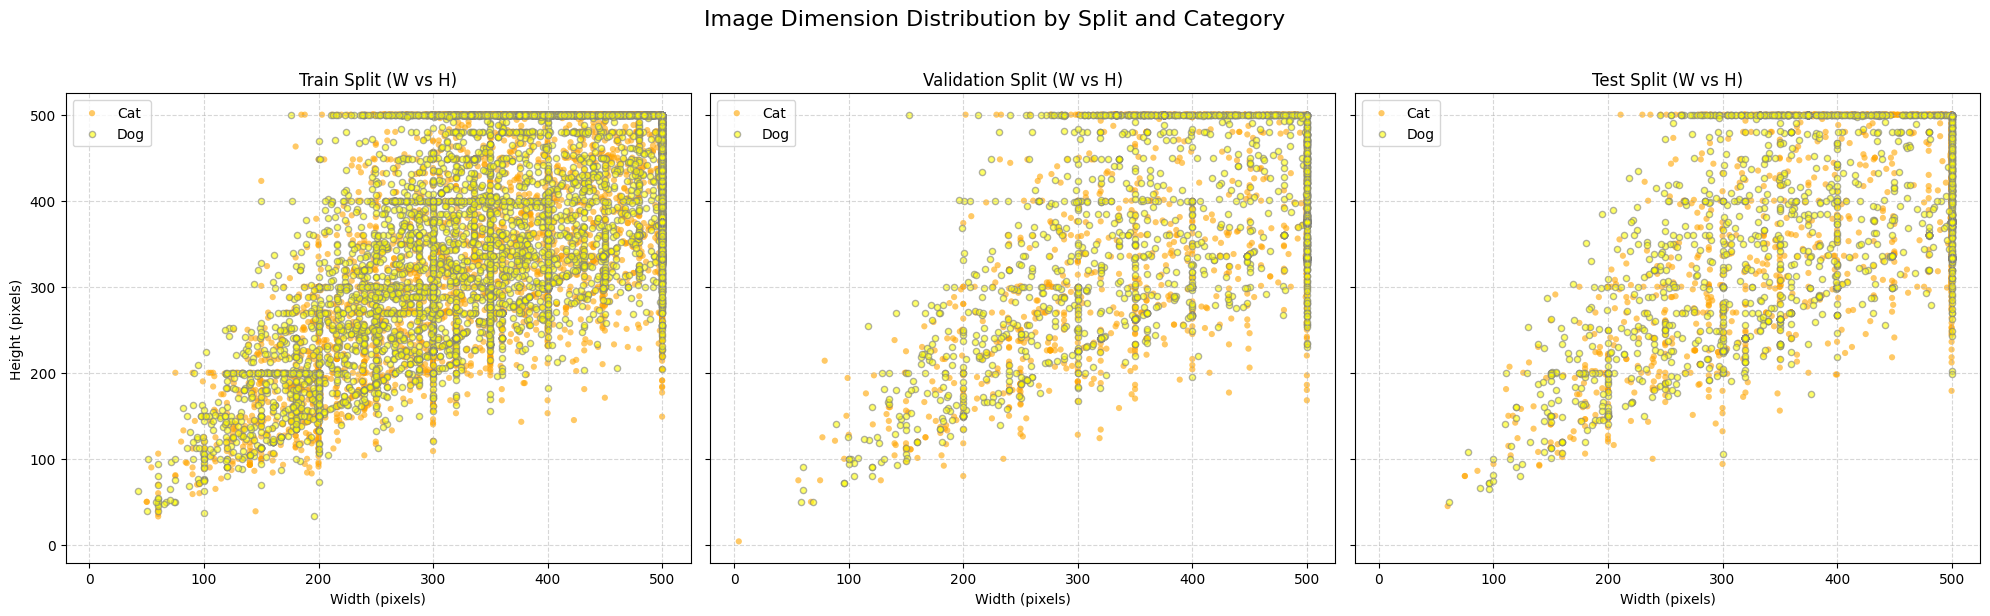

In [6]:
# 2. Plotting Scatter plots of Image Dimensions
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)
colors = {'Cat': 'orange', 'Dog': 'yellow'}

for idx, split in enumerate(splits):
    split_df = df_meta[df_meta['split'] == split]
    ax = axes[idx]

    # Plot Dogs (yellow) and Cats (orange) with edgecolors for better visibility of yellow dots
    for category, color in colors.items():
        subset = split_df[split_df['category'] == category]
        ax.scatter(
            subset['width'],
            subset['height'],
            alpha=0.6,
            c=color,
            label=category,
            edgecolors='gray' if color == 'yellow' else 'none',
            s=20
        )

    ax.set_title(f'{split.capitalize()} Split (W vs H)')
    ax.set_xlabel('Width (pixels)')
    if idx == 0:
        ax.set_ylabel('Height (pixels)')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Image Dimension Distribution by Split and Category', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

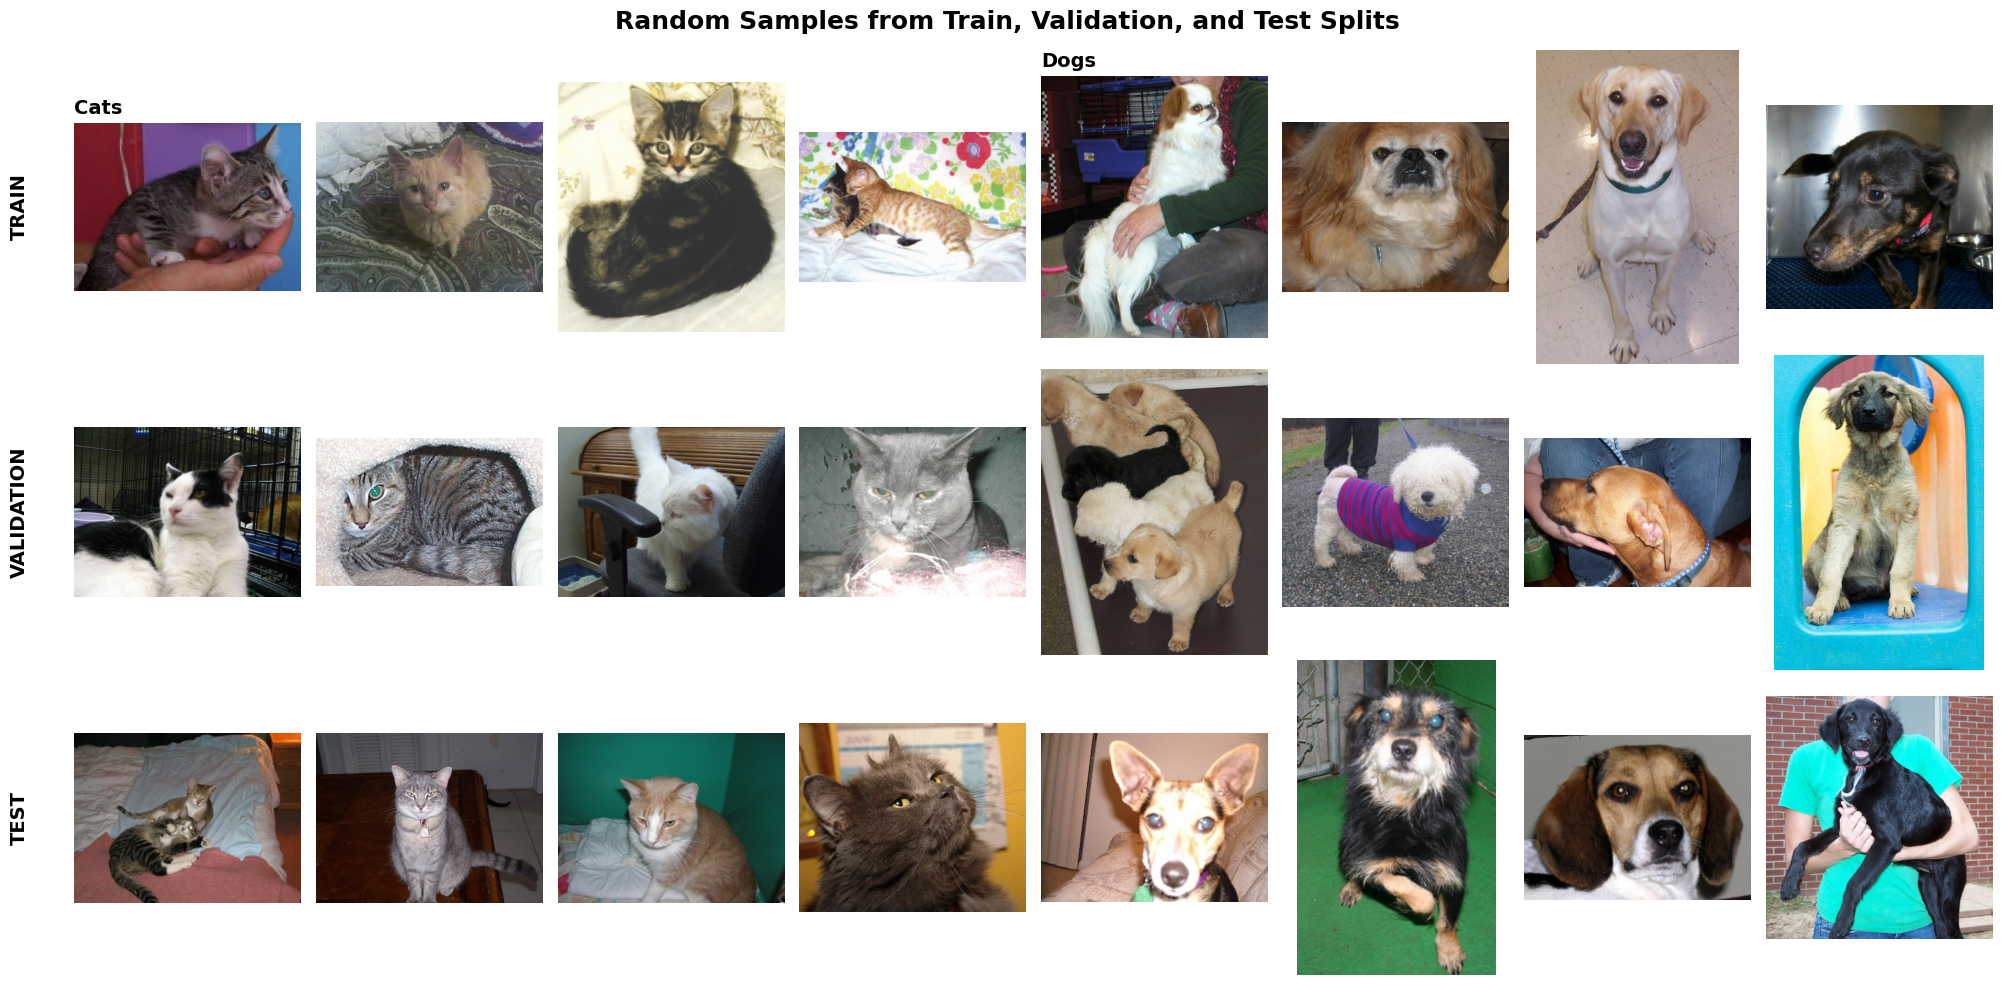

In [8]:
base_split_dir = 'dataset_split'
splits = ['train', 'validation', 'test']
categories = ['Cat', 'Dog']

# Configure plotting grid: 3 rows (one per split), 8 columns (4 Cats, then 4 Dogs)
fig, axes = plt.subplots(3, 8, figsize=(20, 10))

# Fix random seed for reproducibility
random.seed(42)

for split_idx, split in enumerate(splits):
    for cat_idx, category in enumerate(categories):
        folder_path = os.path.join(base_split_dir, split, category)
        all_images = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

        # Select 4 random images
        sampled_images = random.sample(all_images, 4)

        # Plot the sampled images
        for img_idx, img_name in enumerate(sampled_images):
            # Determine subplot column index (0-3 for Cats, 4-7 for Dogs)
            col_idx = (cat_idx * 4) + img_idx
            ax = axes[split_idx, col_idx]

            img_path = os.path.join(folder_path, img_name)
            try:
                with Image.open(img_path) as img:
                    ax.imshow(img)
            except Exception as e:
                # In case of loading error, show a blank placeholder
                ax.text(0.5, 0.5, 'Error', ha='center', va='center', color='red')

            ax.axis('off')

            # Set titles to keep track of columns
            if split_idx == 0 and img_idx == 0:
                ax.set_title(f"{category}s", fontsize=14, weight='bold', loc='left')

    # Add split label to the left of the row
    axes[split_idx, 0].text(-0.2, 0.5, split.upper(), transform=axes[split_idx, 0].transAxes,
                            fontsize=14, weight='bold', va='center', ha='right', rotation=90)

plt.suptitle('Random Samples from Train, Validation, and Test Splits', fontsize=18, weight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [9]:
base_split_dir = 'dataset_split'
splits = ['train', 'validation', 'test']
categories = ['Cat', 'Dog']
target_size = (224, 224)

print("Starting image resizing to 224x224...")

total_resized = 0
for split in splits:
    for category in categories:
        folder_path = os.path.join(base_split_dir, split, category)
        filenames = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

        for f in filenames:
            file_path = os.path.join(folder_path, f)
            try:
                with Image.open(file_path) as img:
                    # Resize using LANCZOS resampling for high-quality downscaling
                    resized_img = img.resize(target_size, Image.Resampling.LANCZOS)
                    # Convert to RGB if needed (handles any grayscale or RGBA exceptions)
                    if resized_img.mode != 'RGB':
                        resized_img = resized_img.convert('RGB')
                    # Overwrite the original image with the resized version
                    resized_img.save(file_path, 'JPEG')
                total_resized += 1
            except Exception as e:
                print(f"Error processing {file_path}: {e}")

print(f"\nSuccessfully resized {total_resized} images to 224x224!")

Starting image resizing to 224x224...


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Successfully resized 24998 images to 224x224!


In [11]:


# 1. Using Keras utility to load and normalize on the fly
batch_size = 32
img_height = 224
img_width = 224

train_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset_split/train',
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Define the normalization layer (scales inputs to [0, 1])
normalization_layer = layers.Rescaling(1./255)

# Apply it to the dataset
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))

# Retrieve a batch to verify scaling
image_batch, labels_batch = next(iter(normalized_ds))
print("TensorFlow Batch min/max pixel values:", image_batch.numpy().min(), "to", image_batch.numpy().max())

Found 17498 files belonging to 2 classes.
TensorFlow Batch min/max pixel values: 0.0 to 1.0


In [12]:
# Verify class names mapping
class_names = train_ds.class_names
print("Class names in order:", class_names)

# Display explicit mapping
label_mapping = {class_name: index for index, class_name in enumerate(class_names)}
print("Explicit Label Mapping:")
for class_name, label in label_mapping.items():
    print(f"  {class_name} -> {label}")

Class names in order: ['Cat', 'Dog']
Explicit Label Mapping:
  Cat -> 0
  Dog -> 1


In [13]:
# 1. Define the Data Augmentation Pipeline
# This sequential model will only run during training mode (it automatically turns off during validation/testing)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),  # Randomly flip images horizontally
    layers.RandomRotation(0.15),      # Randomly rotate images up to 15% (approx 54 degrees)
    layers.RandomZoom(0.15),          # Randomly zoom in/out by up to 15%
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )                                 # Randomly translate images vertically and horizontally by 10%
])

# 2. Apply augmentation only to the training set
# We first rescale (normalize) then augment
augmented_train_ds = train_ds.map(
    lambda x, y: (data_augmentation(normalization_layer(x), training=True), y)
)

print("Data augmentation pipeline defined and successfully chained to the training dataset!")

Data augmentation pipeline defined and successfully chained to the training dataset!


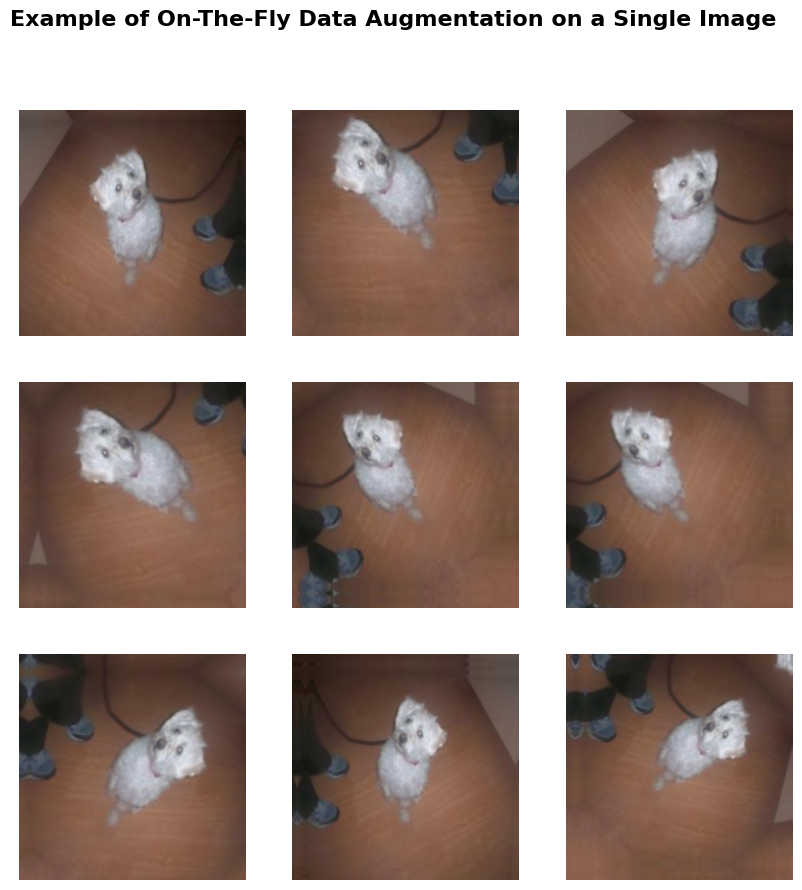

In [15]:
# Visualize the augmentation effect on a single training image
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
    first_image = images[0]
    for i in range(9):
        # Apply the augmentation pipeline directly to the single image
        augmented_image = data_augmentation(tf.expand_dims(first_image, 0)) / 255.0
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_image[0])
        plt.axis("off")

plt.suptitle("Example of On-The-Fly Data Augmentation on a Single Image", fontsize=16, weight='bold')
plt.show()

## Architectural and Mathematical Analysis of the Custom CNN

### 1. Spatial Feature Extraction via 2D Convolutions

Our convolutional layer performs a discrete 2D spatial convolution over the input tensor $\mathbf{X} \in \mathbb{R}^{H \times W \times C}$. For a kernel $\mathbf{K} \in \mathbb{R}^{k \times k \times C \times D}$ and bias vector $\mathbf{b} \in \mathbb{R}^{D}$, the pre-activation mapping $\mathbf{Z} \in \mathbb{R}^{H' \times W' \times D}$ is computed as:

$$Z_{i,j,d} = b_d + \sum_{m=1}^{k} \sum_{n=1}^{k} \sum_{c=1}^{C} X_{i+m-1, \, j+n-1, \, c} \cdot K_{m,n,c,d}$$

To preserve boundary spatial dimensionality (i.e., $H' = H, W' = W$), we employ **half-padding ("same")**. We apply the **Rectified Linear Unit (ReLU)** activation function element-wise to introduce non-linear mapping capabilities:

$$f(x) = \max(0, x)$$

### 2. Batch Normalization (BN)

To mitigate internal covariate shift and stabilize gradient flow throughout deep backpropagation paths, we apply Batch Normalization prior to activation. Over a mini-batch $\mathcal{B} = \{x_{1..m}\}$ of size $m$, the transformation is governed by:

$$\mu_\mathcal{B} = \frac{1}{m}\sum_{i=1}^{m} x_i, \quad \sigma_\mathcal{B}^2 = \frac{1}{m}\sum_{i=1}^{m} (x_i - \mu_\mathcal{B})^2$$

$$\widehat{x}_i = \frac{x_i - \mu_\mathcal{B}}{\sqrt{\sigma_\mathcal{B}^2 + \epsilon}}$$

$$y_i = \gamma \widehat{x}_i + \beta \equiv \text{BN}_{\gamma,\beta}(x_i)$$

where $\gamma$ and $\beta$ are learnable scale and shift parameters, and $\epsilon$ is a hyperparameter for numerical stability.

### 3. Spatial Downsampling via Max Pooling

To achieve translation-invariant representations and reduce spatial dimensionality, we utilize 2D Max Pooling with a kernel size of $2 \times 2$ and stride $s=2$. The mapping reduces spatial resolution by a factor of 4:

$$P_{i,j,d} = \max_{0 \le m, n < 2} Z'_{2i+m, \, 2j+n, \, d}$$

### 4. Regularization: Spatial and Dense Dropout

To combat overfitting during empirical risk minimization, we employ standard element-wise **Dropout**. During training, each neuron activation $h$ is set to zero with probability $p$ drawn from a Bernoulli distribution:

$$r \sim \text{Bernoulli}(1-p), \quad \widetilde{h} = \frac{r \cdot h}{1-p}$$

This prevents co-adaptation of features, forcing the network to learn robust, redundant representations.

### 5. Classification Head & Empirical Risk Function

The feature maps are flattened into a 1D vector $\mathbf{u} \in \mathbb{R}^{d_f}$ and passed to a Dense layer, yielding the logit $z$. The final single-unit output is mapped via the standard logistic sigmoid function to represent the posterior class probability $P(y=1|\mathbf{x})$:

$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

We optimize the network parameters $\Theta$ by minimizing the **Binary Cross-Entropy Loss** with respect to target distribution $y \in \{0, 1\}$:

$$\mathcal{L}(\Theta) = -\frac{1}{N} \sum_{k=1}^{N} \left[ y_k \log(\hat{y}_k) + (1 - y_k) \log(1 - \hat{y}_k) \right] + \lambda \mathcal{R}(\Theta)$$

In [16]:
def create_cnn_model(input_shape=(224, 224, 3)):
    model = models.Sequential([
        # Explicitly define the input shape
        layers.Input(shape=input_shape),

        # First Conv block
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Second Conv block
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Third Conv block
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Fourth Conv block
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Flattening features
        layers.Flatten(),

        # Fully connected layers
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),

        # Output layer: Binary Classification (Sigmoid activation)
        layers.Dense(1, activation='sigmoid')
    ])

    return model

# Instantiate and display model summary
model = create_cnn_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,090,369 (49.94 MB)

 Trainable params: 13,088,641 (49.93 MB)

 Non-trainable params: 1,728 (6.75 KB)

In [17]:
# Compile the model
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.BinaryCrossentropy(),
    metrics=[
        metrics.BinaryAccuracy(name='accuracy'),
        metrics.Precision(name='precision'),
        metrics.Recall(name='recall')
    ]
)

print("Model compiled successfully with Adam optimizer and Binary Crossentropy loss!")

Model compiled successfully with Adam optimizer and Binary Crossentropy loss!


In [18]:
# 1. Load the validation dataset (rescaled exactly like train)
val_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset_split/validation',
    image_size=(224, 224),
    batch_size=32
)

# Normalize validation dataset
normalized_val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# 2. Set up Callbacks to Prevent Overfitting
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# 3. Train the model using the augmented training set and normalized validation set
history = model.fit(
    augmented_train_ds,
    validation_data=normalized_val_ds,
    epochs=20,  # Setting up to 20 epochs, but EarlyStopping will likely trigger earlier
    callbacks=[early_stopping, reduce_lr]
)

Found 3750 files belonging to 2 classes.
Epoch 1/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 321s 548ms/step - accuracy: 0.6153 - loss: 0.7484 - precision: 0.6169 - recall: 0.6088 - val_accuracy: 0.6568 - val_loss: 0.6045 - val_precision: 0.6327 - val_recall: 0.7477 - learning_rate: 0.0010
Epoch 2/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 279s 510ms/step - accuracy: 0.6957 - loss: 0.5812 - precision: 0.7016 - recall: 0.6812 - val_accuracy: 0.7032 - val_loss: 0.5590 - val_precision: 0.7913 - val_recall: 0.5520 - learning_rate: 0.0010
Epoch 3/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 280s 512ms/step - accuracy: 0.7299 - loss: 0.5336 - precision: 0.7360 - recall: 0.7168 - val_accuracy: 0.7528 - val_loss: 0.5160 - val_precision: 0.7678 - val_recall: 0.7248 - learning_rate: 0.0010
Epoch 4/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 284s 519ms/step - accuracy: 0.7552 - loss: 0.5011 - precision: 0.7617 - recall: 0.7427 - val_accuracy: 0.6837 - val_loss: 0.8350 - val_precision: 0.8278 - val_recall: 0.4640 - learning_rate: 0.0010
Epoch 5

In [19]:
# 1. Load the test dataset with the same image size and batch size
test_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset_split/test',
    image_size=(224, 224),
    batch_size=32
)

# 2. Normalize the test dataset
normalized_test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

# 3. Evaluate the model on the normalized test dataset
evaluation_results = model.evaluate(normalized_test_ds)

# 4. Extract and display the metric values
metrics_dict = dict(zip(model.metrics_names, evaluation_results))
print("\n=== TEST SET PERFORMANCE ===")
for metric_name, val in metrics_dict.items():
    print(f"{metric_name.capitalize()}: {val:.4f}")

Found 3750 files belonging to 2 classes.
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8723 - loss: 0.2864 - precision: 0.9480 - recall: 0.7877

=== TEST SET PERFORMANCE ===
Loss: 0.2864
Compile_metrics: 0.8723


In [20]:
# Save the trained model to a file
model_save_path = 'cat_dog_cnn_model.keras'
model.save(model_save_path)

print(f"Model successfully saved to '{model_save_path}'!")

Model successfully saved to 'cat_dog_cnn_model.keras'!


In [21]:
# 1. Load the saved model
model_path = 'cat_dog_cnn_model.keras'
loaded_model = tf.keras.models.load_model(model_path)

# 2. Path to the images directory
images_dir = '/content/images'

# 3. Class mapping based on our label mapping: {0: 'cat', 1: 'dog'}
class_labels = {0: 'cat', 1: 'dog'}

# 4. Iterate and predict for each file in the folder
if os.path.exists(images_dir):
    files = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if not files:
        print(f"No images found in {images_dir}.")
    else:
        for filename in sorted(files):
            file_path = os.path.join(images_dir, filename)
            try:
                # Load and preprocess the image
                img = tf.keras.utils.load_img(file_path, target_size=(224, 224))
                img_array = tf.keras.utils.img_to_array(img)
                # Normalize and expand dimensions to create batch size of 1
                img_array = (img_array / 255.0)
                img_array = np.expand_dims(img_array, axis=0)

                # Make a prediction
                prediction = loaded_model.predict(img_array, verbose=0)[0][0]

                # Determine class based on sigmoid threshold of 0.5
                predicted_class_idx = 1 if prediction >= 0.5 else 0
                predicted_label = class_labels[predicted_class_idx]

                print(f'"{filename}" is a {predicted_label}')
            except Exception as e:
                print(f"Error processing {filename}: {e}")
else:
    print(f"Directory {images_dir} does not exist.")

"catty.jpg" is a cat
"doggo.jpg" is a dog
"doggy.jpg" is a dog
"kitty.jpg" is a cat
